(sec-13-3)=
# 13.3 Event-Related Potentials and Desynchronization

Play a rare high tone among frequent low tones and ask the listener to count the high ones. About a third of a second after each counted tone, the EEG over the parietal scalp shows a positive deflection of a few microvolts, the P300. Ask the same person to open and close the right fist, and the 10 Hz mu rhythm over the left sensorimotor cortex fades for as long as the hand moves. Both are responses to an event, and both are routinely measured, but they are hidden in very different ways. The P300 is smaller than the ongoing EEG, yet it has the same shape and timing on every trial, so averaging the trials reveals it. The mu suppression is a change in the *amplitude* of an oscillation whose phase is unrelated to the event, so plain averaging destroys it, and we need to average power instead.

This distinction, between activity that is phase-locked to an event and activity that is only time-locked to it, organizes the whole section. I derive what averaging does to each kind, then apply the two corresponding toolkits to EEG from the eegmmidb dataset {cite:p}`schalk2004,goldberger2000`. For event-related potentials (ERPs) the dataset has no suitable stimuli, so I add a synthetic ERP of known shape to real resting EEG; this lets us check baseline correction, artifact rejection, standard-error bands and amplitude measures against a ground truth. For event-related desynchronization (ERD) we use real data: one subject opening and closing the left or right fist, recorded at C3 and C4. That subject performed only 15 movement trials, and I try to be honest throughout about how little 15 trials can establish.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import mne
from scipy import signal, stats

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
rng = np.random.default_rng(42)
mne.set_log_level("ERROR")

(sec-13-3-1)=
## 13.3.1 Phase-Locked and Non-Phase-Locked Activity

Consider $N$ trials, each a stretch of EEG $x_i(t)$, $i = 1, \ldots, N$, with time $t$ measured from the event. I model each trial as the sum of three parts:

(eq-13-10)=
\begin{equation*}
x_i(t) = s(t) + a(t)\cos(\omega_0 t + \varphi_i) + v_i(t). \tag{13.10}
\end{equation*}

The first term $s(t)$ is the **evoked** response: the same waveform on every trial, locked in both time and phase to the event. The second is an **induced** oscillation at $\omega_0 = 2\pi f_0$ whose amplitude $a(t)$ follows the event, but whose phase $\varphi_i$ is different on every trial; I take $\varphi_i$ uniformly distributed on $[0, 2\pi)$. The third, $v_i(t)$, is the rest of the EEG, which we treat as zero-mean noise with variance $\sigma^2$, independent of the phases and of the other trials.

**Step 1: the expected value of a trial.** Taking the expectation over trials, the evoked term is deterministic and the noise has zero mean. For the oscillation we average over the uniform phase:

$$
\mathbb{E}\big[\cos(\omega_0 t + \varphi)\big] = \frac{1}{2\pi}\int_0^{2\pi} \cos(\omega_0 t + \varphi)\, d\varphi = \frac{1}{2\pi}\Big[\sin(\omega_0 t + \varphi)\Big]_{\varphi=0}^{2\pi} = 0,
$$

because the sine takes the same value at both limits. Therefore

(eq-13-11)=
\begin{equation*}
\mathbb{E}\big[x_i(t)\big] = s(t). \tag{13.11}
\end{equation*}

The trial average $\bar{x}(t) = \frac{1}{N}\sum_i x_i(t)$ is an unbiased estimate of $s(t)$ and of nothing else. The induced oscillation, however large, has disappeared.

**Step 2: the expected power of a trial.** Now square equation (13.10) before averaging:

$$
\begin{aligned}
x_i^2(t) &= s^2 + a^2\cos^2(\omega_0 t + \varphi_i) + v_i^2 \\
&\quad + 2 s\,a\cos(\omega_0 t + \varphi_i) + 2 s\,v_i + 2 a\cos(\omega_0 t + \varphi_i)\,v_i .
\end{aligned}
$$

The three cross terms have zero expectation: the first by Step 1, the second because $v_i$ has zero mean, and the third because the phase and the noise are independent, so the expectation factors into $\mathbb{E}[\cos(\cdot)]\,\mathbb{E}[v_i] = 0$. For the squared cosine we use $\cos^2\theta = \tfrac{1}{2}(1 + \cos 2\theta)$; the term $\cos(2\omega_0 t + 2\varphi_i)$ also averages to zero over a uniform phase, leaving $\tfrac12$. Hence

(eq-13-12)=
\begin{equation*}
\mathbb{E}\big[x_i^2(t)\big] = s^2(t) + \frac{a^2(t)}{2} + \sigma^2 . \tag{13.12}
\end{equation*}

Averaged *power* keeps the induced oscillation, through its mean power $a^2(t)/2$, together with the evoked power and the noise power. This gives two different recipes. *Average, then square* measures only the phase-locked part. *Square (after band-pass filtering), then average* measures all the power in the band, phase-locked or not. ERPs are measured with the first recipe and ERD with the second.

One more consequence matters in practice. For a finite number of trials the induced term does not vanish exactly from the average: the sum of $N$ unit phasors $e^{j\varphi_i}$ with independent uniform phases has expected squared magnitude $N$ (the cross terms average out), so the average of $N$ of them has magnitude of order $1/\sqrt{N}$. Random-phase oscillations shrink in the average at the same $1/\sqrt{N}$ rate as the noise.

We check these statements on a simulation. Sixty trials contain an evoked response (a negative wave at 100 ms and a positive wave at 300 ms), a 10 Hz oscillation of amplitude 10 µV that is suppressed to 3 µV between about 0.5 and 1.2 s after the event, and white noise with $\sigma = 5$ µV.

In [2]:
def gauss(t, center, width):
    """Unit-height Gaussian bump centered at `center` seconds with standard deviation `width`."""
    return np.exp(-0.5 * ((t - center) / width) ** 2)


def smooth_step(t, t0, t1):
    """Raised-cosine ramp from 0 (t <= t0) to 1 (t >= t1)."""
    r = np.clip((t - t0) / (t1 - t0), 0, 1)
    return 0.5 - 0.5 * np.cos(np.pi * r)


fs_sim, n_sim, sigma = 160.0, 60, 5.0
t_sim = np.arange(int(-1.0 * fs_sim), int(2.5 * fs_sim)) / fs_sim
s_true = -5 * gauss(t_sim, 0.10, 0.025) + 8 * gauss(t_sim, 0.30, 0.07)                     # uV
a_true = 10 * (1 - 0.7 * (smooth_step(t_sim, 0.2, 0.5) - smooth_step(t_sim, 1.2, 1.6)))   # uV
phases = rng.uniform(0, 2 * np.pi, n_sim)
trials = (s_true + a_true * np.cos(2 * np.pi * 10 * t_sim + phases[:, None])
          + rng.normal(0, sigma, (n_sim, t_sim.size)))

pre = t_sim < 0
print(f"Mean power before the event : {np.mean(trials[:, pre] ** 2):6.1f} uV^2  "
      f"(eq. 20.12: a^2/2 + sigma^2 = {10 ** 2 / 2 + sigma ** 2:.1f})")

sos_sim = signal.butter(4, [8, 12], btype="bandpass", fs=fs_sim, output="sos")
bp_trials = signal.sosfiltfilt(sos_sim, trials, axis=1)
bp_average = signal.sosfiltfilt(sos_sim, trials.mean(axis=0))
ratio = np.sqrt(np.mean(bp_average[pre] ** 2) / np.mean(bp_trials[:, pre] ** 2))
print(f"8-12 Hz RMS, average / single trials (before the event): {ratio:.3f}  (1/sqrt(N) = {1 / np.sqrt(n_sim):.3f})")

Mean power before the event :   74.1 uV^2  (eq. 20.12: a^2/2 + sigma^2 = 75.0)
8-12 Hz RMS, average / single trials (before the event): 0.101  (1/sqrt(N) = 0.129)


Before the event the evoked response is zero, so equation (13.12) predicts a mean power of $50 + 25 = 75$ µV², and the simulation agrees. The 10 Hz activity left in the average is about $1/\sqrt{60}$ of its single-trial size, as the phasor argument predicts. The figure shows the two recipes side by side.

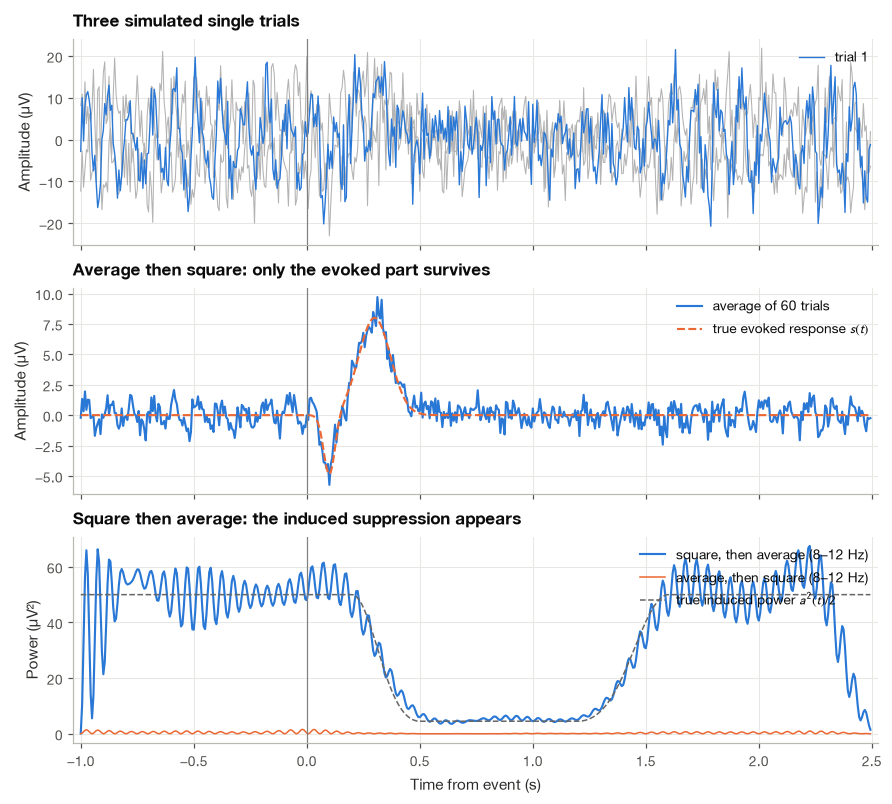

In [3]:
total_power = (bp_trials ** 2).mean(axis=0)     # square, then average
evoked_power = bp_average ** 2                  # average, then square

fig, axes = plt.subplots(3, 1, figsize=(8, 7.2), sharex=True)
for k in (1, 2):
    axes[0].plot(t_sim, trials[k], color="0.7", lw=0.7)
axes[0].plot(t_sim, trials[0], color=C[0], lw=0.9, label="trial 1")
axes[0].set(ylabel="Amplitude (µV)", title="Three simulated single trials")
axes[0].legend(loc="upper right")

axes[1].plot(t_sim, trials.mean(axis=0), color=C[0], label=f"average of {n_sim} trials")
axes[1].plot(t_sim, s_true, "--", color=C[1], label="true evoked response $s(t)$")
axes[1].set(ylabel="Amplitude (µV)", title="Average then square: only the evoked part survives")
axes[1].legend(loc="upper right")

axes[2].plot(t_sim, total_power, color=C[0], label="square, then average (8–12 Hz)")
axes[2].plot(t_sim, evoked_power, color=C[1], lw=1, label="average, then square (8–12 Hz)")
axes[2].plot(t_sim, a_true ** 2 / 2, "--", color="0.4", lw=1, label="true induced power $a^2(t)/2$")
axes[2].set(xlabel="Time from event (s)", ylabel="Power (µV²)",
            title="Square then average: the induced suppression appears")
axes[2].legend(loc="upper right")
for ax in axes:
    ax.axvline(0, color="0.5", lw=0.8)
plt.show()

The top panel shows why single trials are useless by eye: the 8 µV evoked wave is buried in the 10 Hz oscillation and the noise. The average (middle) recovers $s(t)$ and shows no trace of the 10 Hz suppression. The trial-averaged 8–12 Hz power (bottom, blue) follows $a^2(t)/2$, dropping from about 50 µV² to about 5 µV² and recovering, while the power of the average (orange) is close to zero except for a small bump where the evoked response has energy in the 8–12 Hz band.

(sec-13-3-2)=
## 13.3.2 The Averaged ERP: Standard Error and Baseline Correction

With the induced term set aside, equation (13.10) reduces to the ensemble-averaging model of [Section 10.1](../ch16_noise_removal/01_signal_averaging.ipynb), $x_i(t) = s(t) + v_i(t)$. There we derived that the noise variance of the average is $\sigma^2/N$, so the amplitude signal-to-noise ratio grows as $\sqrt{N}$, and that latency jitter turns the average into the true waveform convolved with the jitter distribution. I will not repeat those derivations here. Two further tools are needed to work with real ERPs: a band that shows how uncertain the average is, and a correction for the arbitrary offset of each epoch.

### A standard-error band

The standard deviation of the average at time $t$ is $\sigma(t)/\sqrt{N}$, the **standard error of the mean**. We do not know $\sigma(t)$, but we can estimate it from the spread of the trials around their average at each time point:

(eq-13-13)=
\begin{equation*}
\hat\sigma^2(t) = \frac{1}{N-1}\sum_{i=1}^{N}\big(x_i(t) - \bar{x}(t)\big)^2, \qquad
\widehat{\mathrm{SE}}(t) = \frac{\hat\sigma(t)}{\sqrt{N}} . \tag{13.13}
\end{equation*}

The divisor $N - 1$ makes $\hat\sigma^2$ unbiased: one degree of freedom is used up by estimating $\bar x(t)$ from the same trials. If the noise is approximately Gaussian, $(\bar{x}(t) - s(t))/\widehat{\mathrm{SE}}(t)$ follows Student's $t$ distribution with $N - 1$ degrees of freedom, and

$$
\bar{x}(t) \pm t_{0.975,\,N-1}\,\widehat{\mathrm{SE}}(t)
$$

is a 95% confidence interval for $s(t)$ *at each time point separately*. It is not a band that contains the whole waveform with 95% probability. An ERP of 160 samples will cross outside a pointwise band at several time points by chance alone, so a few isolated excursions of the band away from zero are weak evidence of a response {cite:p}`luck2014`.

### Baseline correction

Slow drifts, electrode polarization and the tails of a high-pass filter give each epoch its own offset. ERP practice removes it by subtracting, from every epoch, its mean over a pre-stimulus **baseline** interval of $M$ samples, typically the 100 to 200 ms before the event. To see what this buys and what it costs, split the noise of trial $i$ into a constant offset $d_i$ (variance $\sigma_d^2$) and a fast component $w_i(t)$, which I take as white with variance $\sigma_w^2$. The corrected epoch is

$$
\begin{aligned}
x_i^{\text{bc}}(t) &= x_i(t) - \frac{1}{M}\sum_{m=1}^{M} x_i(t_m) \\
&= s(t) - \bar{s}_{\text{base}} + \big(d_i - d_i\big) + w_i(t) - \frac{1}{M}\sum_{m=1}^{M} w_i(t_m),
\end{aligned}
$$

where the $t_m$ are the baseline samples and $\bar{s}_{\text{base}}$ is the mean of $s$ over the baseline, which is zero if the response has not started yet. The offset cancels exactly. For a time $t$ after the event, $w_i(t)$ is independent of the baseline samples, so the remaining noise variance is the sum of two variances:

(eq-13-14)=
\begin{equation*}
\operatorname{Var}\big[x_i^{\text{bc}}(t)\big] = \sigma_w^2 + \frac{\sigma_w^2}{M} = \sigma_w^2\left(1 + \frac{1}{M}\right)
\quad\text{instead of}\quad \sigma_d^2 + \sigma_w^2 . \tag{13.14}
\end{equation*}

Baseline correction is worth it whenever $\sigma_d^2 > \sigma_w^2/M$, which with a 200-ms baseline at 160 Hz ($M = 32$) is almost always. Real EEG is not white, so the baseline mean fluctuates more than $\sigma_w^2/M$ suggests, and slow activity in the baseline leaks into the whole corrected epoch. This is one reason to keep the baseline reasonably long and to check that it is free of artifacts. A short simulation confirms equation (13.14).

In [4]:
n_trial, M, sigma_d, sigma_w = 20000, 32, 20.0, 10.0
offsets = rng.normal(0, sigma_d, (n_trial, 1))
epochs_sim = offsets + rng.normal(0, sigma_w, (n_trial, M + 1))      # M baseline samples + one later sample
corrected = epochs_sim[:, -1] - epochs_sim[:, :M].mean(axis=1)
print(f"Variance before correction: {epochs_sim[:, -1].var():6.1f} uV^2  (sigma_d^2 + sigma_w^2 = {sigma_d**2 + sigma_w**2:.1f})")
print(f"Variance after correction : {corrected.var():6.1f} uV^2  (sigma_w^2 (1 + 1/M) = {sigma_w**2 * (1 + 1 / M):.1f})")

Variance before correction:  497.1 uV^2  (sigma_d^2 + sigma_w^2 = 500.0)
Variance after correction :  102.8 uV^2  (sigma_w^2 (1 + 1/M) = 103.1)


(sec-13-3-3)=
## 13.3.3 A Synthetic ERP on Real EEG, Step by Step

The eegmmidb runs contain no stimuli that evoke a clean ERP, so I construct one. The waveform and its scalp distribution below are **synthetic**; only the background EEG is real. This is the same strategy as in [Section 10.1](../ch16_noise_removal/01_signal_averaging.ipynb), extended to all 64 channels so that we can also practice artifact rejection on frontal channels and draw the topography of the result.

### Step 1: Build the synthetic ERP and add it to resting EEG

The synthetic response has two parts. An early negative–positive complex (N1 of $-4$ µV at 100 ms, P2 of $+3$ µV at 190 ms) is centered on Cz, and a P300-like wave of $+10$ µV peaking at 350 ms is centered on Pz. Each part falls off as a Gaussian function of the straight-line distance between electrodes, with a spatial width of 7 cm, so the P300 is largest at Pz, smaller at Cz and nearly zero at the frontopolar sites, roughly as a real P3b would be. We add the response at stimulus times separated by random intervals of 0.9 to 1.1 s to the eyes-open baseline run R01, then band-pass the result from 0.1 to 30 Hz, a common choice for ERPs.

In [5]:
raw01 = mne.io.read_raw_edf("../data/eegmmidb/S001R01.edf", preload=True)
mne.datasets.eegbci.standardize(raw01)
raw01.set_montage("standard_1005")
fs = raw01.info["sfreq"]
ch_names = raw01.ch_names
idx = {name: k for k, name in enumerate(ch_names)}
background = raw01.get_data()[:, :int(60 * fs)] * 1e6                  # uV, 64 x 9600

pos = np.array([ch["loc"][:3] for ch in raw01.info["chs"]])             # electrode positions (m)


def scalp_weight(center, width=0.07):
    """Gaussian fall-off of a synthetic source with distance (m) from electrode `center`."""
    d = np.linalg.norm(pos - pos[idx[center]], axis=1)
    return np.exp(-0.5 * (d / width) ** 2)


t_ep = np.arange(int(-0.2 * fs), int(0.8 * fs)) / fs                    # -200 ... 794 ms
early = -4 * gauss(t_ep, 0.10, 0.02) + 3 * gauss(t_ep, 0.19, 0.03)
p300 = 10 * gauss(t_ep, 0.35, 0.07)
erp_template = np.outer(scalp_weight("Cz"), early) + np.outer(scalp_weight("Pz"), p300)   # 64 x n_t

onsets = [0.5]
while onsets[-1] + 1.1 + 0.8 < 60:
    onsets.append(onsets[-1] + rng.uniform(0.9, 1.1))
onset_idx = np.round(np.array(onsets) * fs).astype(int)

erp_train = np.zeros_like(background)
for k in onset_idx:
    erp_train[:, k + int(round(t_ep[0] * fs)):k + int(round(t_ep[0] * fs)) + t_ep.size] += erp_template

sos_erp = signal.butter(2, [0.1, 30], btype="bandpass", fs=fs, output="sos")
eeg_task = signal.sosfiltfilt(sos_erp, background + erp_train, axis=1)
erp_filtered = signal.sosfiltfilt(sos_erp, erp_train, axis=1)            # the response alone, same filter
print(f"{onset_idx.size} synthetic stimuli; template weights at Pz, Cz, Fz, Fp1: "
      + ", ".join(f"{scalp_weight('Pz')[idx[c]]:.2f}" for c in ("Pz", "Cz", "Fz", "Fp1")))
print(f"Background SD at Pz after filtering: {signal.sosfiltfilt(sos_erp, background[idx['Pz']]).std():.1f} uV")

60 synthetic stimuli; template weights at Pz, Cz, Fz, Fp1: 1.00, 0.57, 0.13, 0.03
Background SD at Pz after filtering: 51.5 uV


Because filtering is linear, filtering the response train alone (`erp_filtered`) tells us exactly what the filtered ERP looks like without any background. Its epoch average is our ground truth. Note the size of the problem: the background at Pz has a standard deviation several times the 10 µV peak of the P300.

### Step 2: Cut the epochs and correct the baseline

In [6]:
def epoch(x, onset_idx, fs, tmin, tmax):
    """Cut epochs [tmin, tmax) s around each onset sample; returns (n_trials, n_channels, n_times)."""
    n0, n_len = int(round(tmin * fs)), int(round((tmax - tmin) * fs))
    return np.stack([x[..., k + n0:k + n0 + n_len] for k in onset_idx])


def baseline_correct(ep, t, t_base=(-0.2, 0.0)):
    """Subtract each epoch's mean over the baseline interval (eq. 20.14)."""
    base = (t >= t_base[0]) & (t < t_base[1])
    return ep - ep[..., base].mean(axis=-1, keepdims=True)


epochs_raw = epoch(eeg_task, onset_idx, fs, -0.2, 0.8)
epochs_bc = baseline_correct(epochs_raw, t_ep)
truth = baseline_correct(epoch(erp_filtered, onset_idx, fs, -0.2, 0.8), t_ep).mean(axis=0)

k350 = np.argmin(np.abs(t_ep - 0.35))
print(f"Epochs: {epochs_bc.shape[0]} trials x {epochs_bc.shape[1]} channels x {epochs_bc.shape[2]} samples")
print(f"Across-trial SD at Pz, 350 ms: {epochs_raw[:, idx['Pz'], k350].std(ddof=1):.1f} uV before, "
      f"{epochs_bc[:, idx['Pz'], k350].std(ddof=1):.1f} uV after baseline correction")

Epochs: 60 trials x 64 channels x 160 samples
Across-trial SD at Pz, 350 ms: 61.4 uV before, 72.6 uV after baseline correction


### Step 3: Reject epochs contaminated by eye artifacts

Eye blinks and eye movements produce large slow deflections that are strongest at the frontopolar electrodes ([Section 13.1.6](01_eeg_fundamentals.ipynb)). The simplest rejection rule is a peak-to-peak threshold on Fp1 and Fp2. The textbook value of 100 µV does not transfer to every recording, so we first look at the distribution.

In [7]:
ptp_front = np.ptp(epochs_bc[:, [idx["Fp1"], idx["Fp2"]], :], axis=-1).max(axis=1)
print("Peak-to-peak at Fp1/Fp2 (uV), percentiles 10/50/90/100: "
      + " / ".join(f"{v:.0f}" for v in np.percentile(ptp_front, [10, 50, 90, 100])))

threshold = 300.0                                       # uV, chosen from the distribution above
keep = ptp_front < threshold
epochs_ok = epochs_bc[keep]
print(f"Threshold {threshold:.0f} uV: rejected {np.sum(~keep)} of {keep.size} epochs, kept {keep.sum()}")

Peak-to-peak at Fp1/Fp2 (uV), percentiles 10/50/90/100: 118 / 169 / 589 / 1016
Threshold 300 uV: rejected 14 of 60 epochs, kept 46


In this subject even artifact-free one-second epochs span well over 100 µV at Fp1, partly because the eyes-open EEG contains continual small eye movements. A rule of thumb would have rejected nearly everything. I chose 300 µV after looking at the distribution: it removes the epochs dominated by the largest eye movements and keeps most of the data. Rejection is only safe when artifacts are unrelated to the stimulus. Here the stimuli are synthetic and the blinks cannot know about them; in a real experiment, where people tend to blink after a target, rejection can bias the average, and correction methods such as independent component analysis (Section 25.2) are often preferred.

### Step 4: Average with a standard-error band

In [8]:
def average_with_ci(ep, level=0.95):
    """Trial average, standard error (eq. 20.13) and pointwise t-based confidence half-width."""
    n = ep.shape[0]
    se = ep.std(axis=0, ddof=1) / np.sqrt(n)
    return ep.mean(axis=0), se, stats.t.ppf(0.5 + level / 2, n - 1) * se


avg, se, half = average_with_ci(epochs_ok)
pz = idx["Pz"]
covered = np.mean(np.abs(avg[pz] - truth[pz]) <= half[pz])
print(f"Mean standard error at Pz      : {se[pz].mean():.2f} uV")
print(f"Background SD / sqrt(N)         : {epochs_ok[:, pz, :].std(ddof=1, axis=0).mean() / np.sqrt(keep.sum()):.2f} uV")
print(f"Time points where the 95% band covers the truth: {100 * covered:.0f}%")

Mean standard error at Pz      : 7.49 uV
Background SD / sqrt(N)         : 7.49 uV
Time points where the 95% band covers the truth: 98%


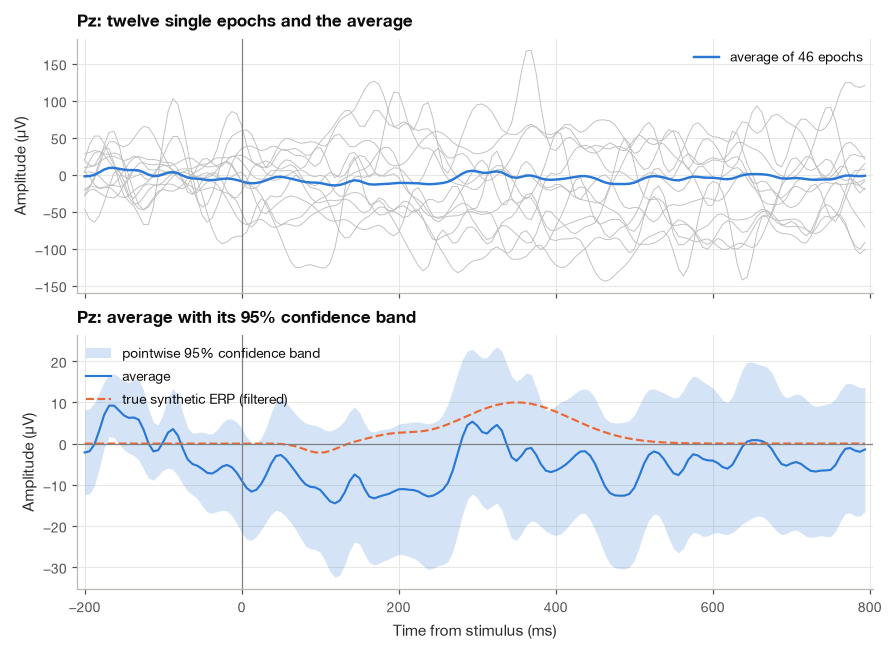

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5.8), sharex=True)
for ep in epochs_ok[:12, pz]:
    axes[0].plot(1000 * t_ep, ep, color="0.75", lw=0.6)
axes[0].plot(1000 * t_ep, avg[pz], color=C[0], lw=1.6, label=f"average of {keep.sum()} epochs")
axes[0].set(ylabel="Amplitude (µV)", title="Pz: twelve single epochs and the average")
axes[0].legend(loc="upper right")

axes[1].fill_between(1000 * t_ep, avg[pz] - half[pz], avg[pz] + half[pz], color=C[0], alpha=0.2, lw=0,
                     label="pointwise 95% confidence band")
axes[1].plot(1000 * t_ep, avg[pz], color=C[0], label="average")
axes[1].plot(1000 * t_ep, truth[pz], "--", color=C[1], label="true synthetic ERP (filtered)")
axes[1].axhline(0, color="0.5", lw=0.8)
axes[1].set(xlabel="Time from stimulus (ms)", ylabel="Amplitude (µV)", title="Pz: average with its 95% confidence band")
axes[1].legend(loc="upper left")
for ax in axes:
    ax.axvline(0, color="0.5", lw=0.8)
plt.show()

The single epochs give no hint of a response. The average shows a clear positive wave peaking near 350 ms, and the confidence band contains the true waveform at most time points. The band is wide, though: with this subject's background the half-width is around XX µV, so a 10 µV P300 is detected comfortably, but an effect of 2 to 3 µV, the size of many differences between experimental conditions, would not be.

### Step 5: Measure the P300 amplitude and latency

Two amplitude measures are common. The **peak amplitude** is the largest value of the average in a search window (here 250–500 ms), and the **peak latency** is where it occurs. The **mean amplitude** is the average of the waveform over a fixed window chosen in advance (here 300–450 ms). The peak is easy to explain but has a statistical flaw: the maximum of a noisy curve is biased upwards, because noise that happens to push a sample up is selected while noise that pushes it down is ignored. The mean amplitude is a linear function of the data, so its expectation equals the mean amplitude of the true ERP for any number of trials {cite:p}`luck2014`. We check both claims by averaging random subsets of the kept epochs.

In [10]:
peak_win = (t_ep >= 0.25) & (t_ep <= 0.50)
mean_win = (t_ep >= 0.30) & (t_ep <= 0.45)
true_peak, true_mean = truth[pz, peak_win].max(), truth[pz, mean_win].mean()

rows = []
for n in (5, 10, 20, keep.sum()):
    peaks, means, lats = [], [], []
    for _ in range(400):
        sub = epochs_ok[rng.choice(keep.sum(), n, replace=False), pz].mean(axis=0)
        peaks.append(sub[peak_win].max())
        lats.append(1000 * t_ep[peak_win][np.argmax(sub[peak_win])])
        means.append(sub[mean_win].mean())
    rows.append({"Trials": n, "Peak amplitude (uV)": np.mean(peaks), "SD of peak": np.std(peaks),
                 "Mean amplitude (uV)": np.mean(means), "SD of mean": np.std(means),
                 "Peak latency SD (ms)": np.std(lats)})
print(f"Truth: peak amplitude {true_peak:.2f} uV at {1000 * t_ep[peak_win][np.argmax(truth[pz, peak_win])]:.0f} ms, "
      f"mean amplitude {true_mean:.2f} uV")
pd.DataFrame(rows).set_index("Trials").round(2)

Truth: peak amplitude 10.00 uV at 350 ms, mean amplitude 7.93 uV


,Peak amplitude (uV),SD of peak,Mean amplitude (uV),SD of mean,Peak latency SD (ms)
Trials,,,,,
5,20.41,23.09,-3.84,21.78,70.62
10,14.60,15.59,-1.71,14.13,63.19
20,8.67,9.19,-2.27,8.49,52.96
46,5.33,0.00,-1.99,0.00,0.00


The table shows the bias directly. With five trials the peak amplitude averages XX µV against a true peak of XX µV, and the bias shrinks as trials are added but has not vanished at XX trials. The mean amplitude stays close to its true value at every $N$, and it is also less variable. The peak latency is the least reliable measure of all with few trials, wandering by tens of milliseconds. When I compare ERP amplitudes between conditions or groups, I use mean amplitudes over windows fixed before looking at the data, for exactly these reasons.

### Step 6: Draw the topography of the response

Finally, we compute the mean amplitude in the 300–450 ms window at every channel and draw it as a scalp map next to the true synthetic map.

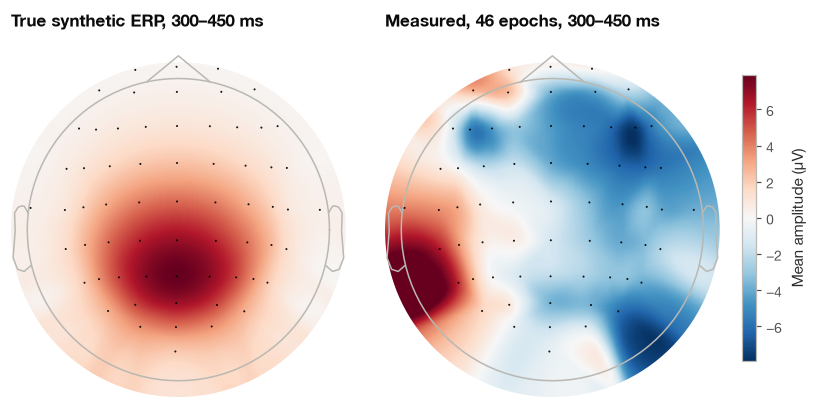

Correlation between measured and true topographies across 64 channels: r = 0.06


In [11]:
topo_meas = avg[:, mean_win].mean(axis=1)
topo_true = truth[:, mean_win].mean(axis=1)
vmax = np.abs(np.concatenate([topo_meas, topo_true])).max()

fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.6))
for ax, values, title in ((axes[0], topo_true, "True synthetic ERP"), (axes[1], topo_meas, f"Measured, {keep.sum()} epochs")):
    im, _ = mne.viz.plot_topomap(values, raw01.info, axes=ax, show=False, cmap="RdBu_r",
                                 vlim=(-vmax, vmax), contours=0, sensors=True)
    ax.set_title(f"{title}, 300–450 ms")
cbar = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.03)
cbar.set_label("Mean amplitude (µV)")
plt.show()

r = np.corrcoef(topo_meas, topo_true)[0, 1]
print(f"Correlation between measured and true topographies across 64 channels: r = {r:.2f}")

The measured map reproduces the parietal maximum of the synthetic P300, with noise visible at the edges of the head where the true response is near zero. A topography is often the quickest sanity check on an ERP: a "P300" whose maximum sits over the frontopolar electrodes is more likely to be eye activity than a P300.

(sec-13-3-4)=
## 13.3.4 Event-Related Desynchronization and Synchronization

### The mu and beta rhythms around a movement

Over the sensorimotor cortex the resting EEG contains the **mu rhythm**, an 8–13 Hz oscillation with an arch-shaped waveform that is best recorded at C3 and C4, and beta activity at roughly 13–30 Hz. Both are attenuated when a person moves, prepares to move, imagines a movement or watches one. Following {cite:t}`pfurtscheller1999`, a decrease in band power relative to a reference period is called **event-related desynchronization** (ERD), on the reasoning of [Section 13.1.1](01_eeg_fundamentals.ipynb) that a smaller scalp signal reflects less synchronized activity in the underlying population, and an increase is called **event-related synchronization** (ERS). For hand movements, the mu and beta ERD are typically larger over the hemisphere contralateral to the moving hand, at least early on, and beta power often rebounds above its resting level within about a second after the movement ends, the post-movement beta ERS. These patterns are the basis of motor-imagery brain–computer interfaces.

### Quantifying ERD

The classical procedure follows directly from equation (13.12): band-pass filter each trial to the band of interest, square the samples to obtain instantaneous power, average across trials, and smooth over a short window. Call the result $P(t)$. With $R$ the mean of $P(t)$ over a reference interval before the event, the ERD is expressed in percent as

(eq-13-15)=
\begin{equation*}
\mathrm{ERD}(t) = \frac{P(t) - R}{R}\times 100\% . \tag{13.15}
\end{equation*}

Negative values are desynchronization and positive values synchronization. The scale is asymmetric: power can fall by at most 100%, but it can rise by any amount. Expressing the same ratio in decibels, $10\log_{10}(P/R)$, restores the symmetry, and the two are related by $\mathrm{ERD} = 100\,(10^{\,\mathrm{dB}/10} - 1)$; a 50% ERD is $-3.0$ dB and a 100% ERS is $+3.0$ dB.

Equation (13.12) also shows that $P(t)$ contains the power of any evoked response in the band. To measure the induced part alone, we can subtract the trial average from each band-passed trial before squaring. The resulting **intertrial variance**

(eq-13-16)=
\begin{equation*}
P_{\text{ITV}}(t) = \frac{1}{N-1}\sum_{i=1}^{N}\big(y_i(t) - \bar{y}(t)\big)^2 , \tag{13.16}
\end{equation*}

where $y_i$ is the band-passed trial, has expectation $a^2(t)/2 + \sigma^2$: the $s^2(t)$ term of (13.12) is gone, because subtracting the average removes the component common to all trials. The $N - 1$ divisor plays the same role as in (13.13). When the evoked response has little energy in the band, the two methods agree.

(sec-13-3-5)=
## 13.3.5 Mu and Beta ERD during Hand Movement, Step by Step

In run R03 of eegmmidb, a target appears on the left or right side of a screen and the subject opens and closes the corresponding fist until the target disappears, about 4.1 s later; a rest period of about 4.2 s follows. Annotation T1 marks left-fist trials and T2 right-fist trials. We analyze C3 (over the left sensorimotor cortex) and C4 (over the right) in the referential montage of the recording.

### Step 1: Load the run and find the events

In [12]:
raw03 = mne.io.read_raw_edf("../data/eegmmidb/S001R03.edf", preload=True)
mne.datasets.eegbci.standardize(raw03)
raw03.set_montage("standard_1005")
x03 = raw03.get_data(picks=["C3", "C4"]) * 1e6                        # uV, 2 x N
tmin, tmax = -2.5, 6.5


def event_samples(raw, label, n_total):
    """Onset samples of annotation `label` whose [tmin, tmax) epoch lies inside the record."""
    on = np.round(raw.annotations.onset[raw.annotations.description == label] * fs).astype(int)
    return on[(on + tmin * fs >= 0) & (on + tmax * fs <= n_total)]


events03 = {"Left fist": event_samples(raw03, "T1", x03.shape[1]),
            "Right fist": event_samples(raw03, "T2", x03.shape[1])}
dur = raw03.annotations.duration
print(f"Record: {x03.shape[1] / fs:.1f} s; task periods {dur[raw03.annotations.description != 'T0'].mean():.1f} s, "
      f"rest periods {dur[raw03.annotations.description == 'T0'].mean():.1f} s")
for cls, ev in events03.items():
    print(f"{cls:<10s}: {ev.size} trials with a complete epoch from {tmin} to {tmax} s")

Record: 125.0 s; task periods 4.1 s, rest periods 4.2 s
Left fist : 7 trials with a complete epoch from -2.5 to 6.5 s
Right fist: 7 trials with a complete epoch from -2.5 to 6.5 s


### Step 2: Filter into the mu and beta bands, then cut epochs

We filter the continuous signals and cut epochs afterwards. Filtering short epochs would add transients at both ends of every epoch, exactly where the reference interval lies.

In [13]:
bands = {"mu (8-13 Hz)": (8, 13), "beta (13-30 Hz)": (13, 30)}
t_erd = np.arange(int(tmin * fs), int(tmax * fs)) / fs


def band_epochs(x, onsets, f_band):
    """Zero-phase band-pass of the continuous signal, then epochs [tmin, tmax)."""
    sos = signal.butter(4, f_band, btype="bandpass", fs=fs, output="sos")
    return epoch(signal.sosfiltfilt(sos, x, axis=-1), onsets, fs, tmin, tmax)


bp03 = {(b, cls): band_epochs(x03, ev, f_band) for b, f_band in bands.items() for cls, ev in events03.items()}
print(f"Epoch array for one band and class: {bp03[('mu (8-13 Hz)', 'Left fist')].shape} (trials, channels, samples)")

Epoch array for one band and class: (7, 2, 1440) (trials, channels, samples)


### Step 3: Compute the ERD time courses

In [14]:
def erd_percent(ep, t, ref=(-2.0, -0.5), smooth_s=0.5, intertrial=False):
    """ERD/ERS in percent (eq. 20.15) from band-passed epochs (trials, channels, samples)."""
    if intertrial:                                     # eq. (20.16): remove the phase-locked part
        power = ep.var(axis=0, ddof=1)
    else:
        power = (ep ** 2).mean(axis=0)
    n_smooth = int(smooth_s * fs)
    power = np.apply_along_axis(np.convolve, -1, power, np.ones(n_smooth) / n_smooth, mode="same")
    in_ref = (t >= ref[0]) & (t < ref[1])
    R = power[..., in_ref].mean(axis=-1, keepdims=True)
    return 100 * (power - R) / R


erd03 = {key: erd_percent(ep, t_erd) for key, ep in bp03.items()}
active = (t_erd >= 0.5) & (t_erd < 3.5)
rows = []
for (b, cls), e in erd03.items():
    rows.append({"Band": b, "Class": cls, "C3 ERD (%)": e[0, active].mean(), "C4 ERD (%)": e[1, active].mean()})
itv = erd_percent(bp03[("mu (8-13 Hz)", "Right fist")], t_erd, intertrial=True)
print(f"Classical vs intertrial-variance ERD, mu, right fist, C3: largest difference "
      f"{np.abs(itv[0] - erd03[('mu (8-13 Hz)', 'Right fist')][0]).max():.1f} percentage points")
pd.DataFrame(rows).set_index(["Band", "Class"]).round(1)

Classical vs intertrial-variance ERD, mu, right fist, C3: largest difference 12.7 percentage points


C3 ERD (%)  C4 ERD (%)
Band            Class                             
mu (8-13 Hz)    Left fist        -24.0       -43.2
                Right fist       -31.6       -19.9
beta (13-30 Hz) Left fist        -25.0       -22.8
                Right fist       -17.7       -22.0

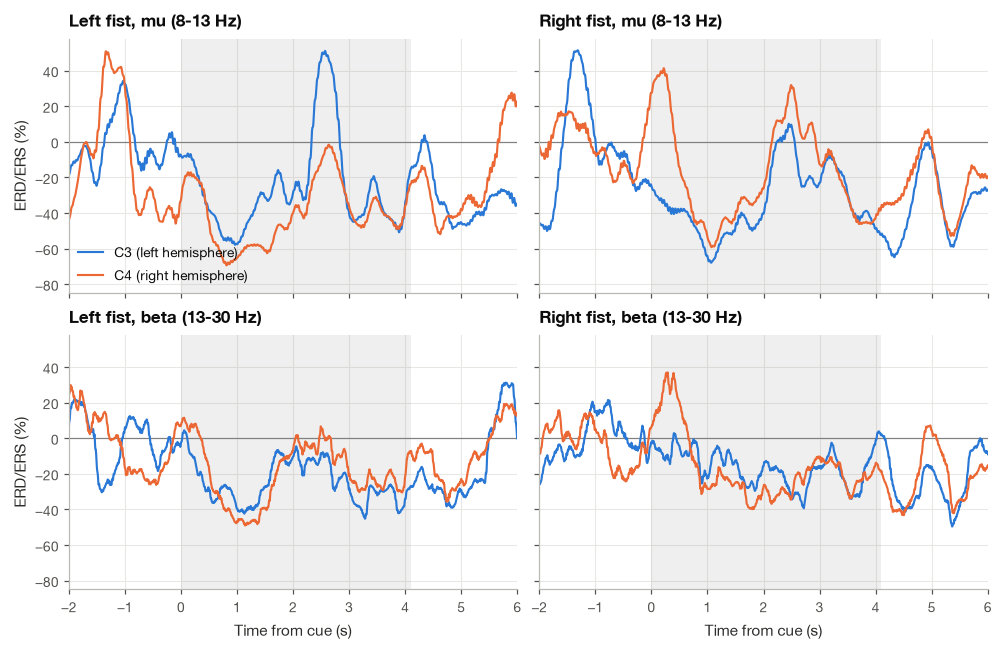

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5.8), sharex=True, sharey=True)
for row, b in enumerate(bands):
    for col, cls in enumerate(("Left fist", "Right fist")):
        ax = axes[row, col]
        e = erd03[(b, cls)]
        ax.axvspan(0, 4.1, color="0.5", alpha=0.12, lw=0)
        ax.axhline(0, color="0.5", lw=0.8)
        ax.plot(t_erd, e[0], color=C[0], label="C3 (left hemisphere)")
        ax.plot(t_erd, e[1], color=C[1], label="C4 (right hemisphere)")
        ax.set_title(f"{cls}, {b}")
        if col == 0:
            ax.set_ylabel("ERD/ERS (%)")
        if row == 1:
            ax.set_xlabel("Time from cue (s)")
axes[0, 0].legend(loc="lower left")
axes[0, 0].set_xlim(tmin + 0.5, tmax - 0.5)
plt.show()

The shaded region is the movement period. In the mu band, power falls within about a second of the cue and stays low while the fist opens and closes. For left-fist trials the ERD is deeper at C4, over the right hemisphere; for right-fist trials it is deeper at C3. This is the expected contralateral pattern, although its size, XX versus XX percentage points, is modest. In the beta band the ERD is present at both electrodes for both hands with no consistent lateralization, and there is no clear post-movement rebound: after the target disappears beta power recovers towards the reference level but does not exceed it. One possible reason is the design. Rest periods last only about 4 s, so the reference interval, 2 to 0.5 s before the cue, falls within a second or two after the end of the previous movement, when a rebound may still be in progress; a raised reference would hide a rebound and exaggerate the ERD. The classical and intertrial-variance estimates are almost identical in the mu band, which tells us that phase-locked activity contributes little here.

### Step 4: Look at the single trials and the uncertainty

Grand-average curves hide how variable the trials are. For each trial we compute the band power in the active window (0.5–3.5 s) relative to that trial's own reference interval, in decibels, and summarize each condition by its mean with a bootstrap 95% confidence interval: we resample the trials with replacement many times, recompute the mean each time, and take the 2.5th and 97.5th percentiles of the resampled means.

In [16]:
def trial_db(ep, t, active=(0.5, 3.5), ref=(-2.0, -0.5)):
    """Per-trial band power change, active window relative to reference, in dB (trials x channels)."""
    p = ep ** 2
    A = p[..., (t >= active[0]) & (t < active[1])].mean(axis=-1)
    R = p[..., (t >= ref[0]) & (t < ref[1])].mean(axis=-1)
    return 10 * np.log10(A / R)


def bootstrap_ci(values, n_boot=5000):
    """Percentile bootstrap 95% confidence interval of the mean."""
    means = rng.choice(values, (n_boot, values.size), replace=True).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


mu_db = {cls: trial_db(bp03[("mu (8-13 Hz)", cls)], t_erd) for cls in events03}
rows = []
for cls, d in mu_db.items():
    for ch, k in (("C3", 0), ("C4", 1)):
        lo, hi = bootstrap_ci(d[:, k])
        rows.append({"Class": cls, "Channel": ch, "Mean (dB)": d[:, k].mean(), "95% CI low": lo, "95% CI high": hi})
    lat = d[:, 0] - d[:, 1]                             # C3 minus C4: negative = stronger ERD on the left
    expected = np.sum(lat > 0) if cls == "Left fist" else np.sum(lat < 0)
    print(f"{cls:<10s}: C3 - C4 = {lat.mean():+.2f} dB, 95% CI [{bootstrap_ci(lat)[0]:+.2f}, {bootstrap_ci(lat)[1]:+.2f}]; "
          f"contralateral in {expected} of {lat.size} trials")
pd.DataFrame(rows).set_index(["Class", "Channel"]).round(2)

Left fist : C3 - C4 = +0.70 dB, 95% CI [-0.57, +1.90]; contralateral in 5 of 7 trials
Right fist: C3 - C4 = -0.34 dB, 95% CI [-1.83, +1.43]; contralateral in 5 of 7 trials


Mean (dB)  95% CI low  95% CI high
Class      Channel                                    
Left fist  C3           -1.00       -1.90         0.20
           C4           -1.71       -2.95        -0.56
Right fist C3           -1.25       -2.84         0.22
           C4           -0.91       -2.52         0.70

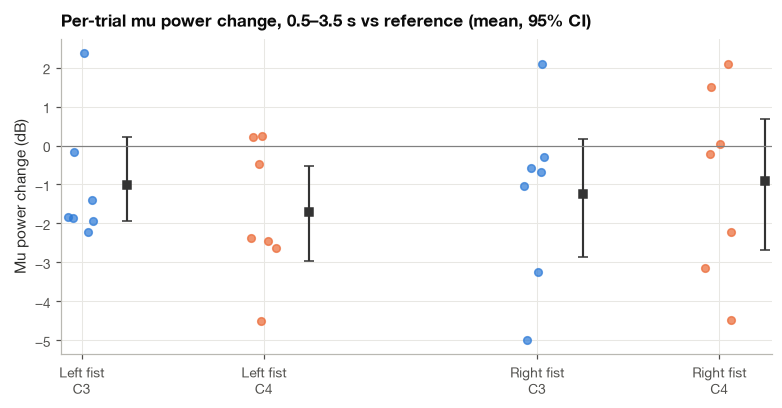

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.6))
x_pos = 0
ticks, labels = [], []
for cls, d in mu_db.items():
    for ch, k, color in (("C3", 0, C[0]), ("C4", 1, C[1])):
        jitter = rng.uniform(-0.08, 0.08, d.shape[0])
        ax.plot(x_pos + jitter, d[:, k], "o", color=color, ms=5, alpha=0.7)
        lo, hi = bootstrap_ci(d[:, k])
        ax.errorbar(x_pos + 0.25, d[:, k].mean(), yerr=[[d[:, k].mean() - lo], [hi - d[:, k].mean()]],
                    fmt="s", color="0.2", ms=5, capsize=3)
        ticks.append(x_pos)
        labels.append(f"{cls}\n{ch}")
        x_pos += 1
    x_pos += 0.5
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xticks(ticks, labels)
ax.set(ylabel="Mu power change (dB)", title="Per-trial mu power change, 0.5–3.5 s vs reference (mean, 95% CI)")
plt.show()

Every single trial shows a mu power decrease at both electrodes, so the existence of a movement-related ERD is not in doubt even with seven or eight trials. The lateralization is a different matter. The mean difference between hemispheres points in the contralateral direction for both hands, but the bootstrap intervals of the C3 and C4 means overlap broadly, and only XX of the 15 trials individually show the stronger ERD on the contralateral side. With so few trials, a careful report would say that the data are *consistent with* contralateral dominance, not that they demonstrate it. A bootstrap interval from seven values is itself rough; it tends to be too narrow for very small samples, which strengthens rather than weakens this caution.

### Step 5: Check the result on imagined movement and another montage

Run R04 has exactly the same design, but the subject only *imagines* opening and closing the fist. We repeat the mu-band analysis on R04 and, for both runs, with a small Laplacian derivation (each of C3 and C4 minus the mean of its four nearest neighbors, equation (13.4) of [Section 13.1.4](01_eeg_fundamentals.ipynb)).

In [18]:
neighbors = {"C3": ("FC3", "CP3", "C1", "C5"), "C4": ("FC4", "CP4", "C2", "C6")}
rows = []
for run in ("R03", "R04"):
    raw = mne.io.read_raw_edf(f"../data/eegmmidb/S001{run}.edf", preload=True)
    mne.datasets.eegbci.standardize(raw)
    raw.set_montage("standard_1005")
    data = raw.get_data() * 1e6
    names = raw.ch_names
    montages = {"Referential": np.stack([data[names.index(c)] for c in ("C3", "C4")]),
                "Laplacian": np.stack([data[names.index(c)] - data[[names.index(n) for n in neighbors[c]]].mean(axis=0)
                                       for c in ("C3", "C4")])}
    for montage, x in montages.items():
        row = {"Run": f"{run} ({'real' if run == 'R03' else 'imagined'})", "Montage": montage}
        for label, cls in (("T1", "Left"), ("T2", "Right")):
            e = erd_percent(band_epochs(x, event_samples(raw, label, x.shape[1]), (8, 13)), t_erd)
            row[f"{cls}: C3"], row[f"{cls}: C4"] = e[0, active].mean(), e[1, active].mean()
        rows.append(row)
pd.DataFrame(rows).set_index(["Run", "Montage"]).round(0)

Left: C3  Left: C4  Right: C3  Right: C4
Run            Montage                                              
R03 (real)     Referential     -24.0     -43.0      -32.0      -20.0
               Laplacian       -61.0     -60.0      -48.0      -56.0
R04 (imagined) Referential     -29.0     -17.0      -36.0      -19.0
               Laplacian       -45.0     -44.0      -68.0      -21.0

The table is a lesson in humility. With the referential montage, imagined right-fist movement produces a contralateral mu ERD (stronger at C3) of similar size to the real movement, but imagined left-fist movement does not show the expected stronger ERD at C4. The Laplacian derivation, which removes activity shared with the neighboring electrodes, makes the ERD deeper at both sites and, for this subject, erases most of the lateralization even for real movement. Motor imagery in people without training is known to produce weaker and less consistent ERD than real movement, and laterality estimated from 7 or 8 trials per class is fragile. A study that wanted to claim a lateralized ERD would need many more trials, several subjects, a pre-registered montage and analysis window, and a statistical test across trials or subjects.

(sec-13-3-6)=
## 13.3.6 A Simple Time–Frequency Map of ERD

Choosing the mu and beta bands in advance assumes we know where the reactive frequencies are, and they vary between people. A time–frequency map removes that assumption: we repeat the ERD computation in many narrow bands and display the result as an image with time on the horizontal axis and frequency on the vertical axis. Here I use 2-Hz-wide bands centered on every integer frequency from 6 to 34 Hz, each implemented as a fourth-order Butterworth band-pass filter. This filter-bank approach is the most direct generalization of Step 3; Chapter 23 develops the spectrogram and the wavelet transform, which compute the same kind of map more efficiently and with better-understood resolution.

In [19]:
centers = np.arange(6, 35)
tf_maps = {cls: np.empty((2, centers.size, t_erd.size)) for cls in events03}
for i, fc in enumerate(centers):
    for cls, ev in events03.items():
        tf_maps[cls][:, i, :] = erd_percent(band_epochs(x03, ev, (fc - 1, fc + 1)), t_erd)

for cls, m in tf_maps.items():
    for ch, k in (("C3", 0), ("C4", 1)):
        mean_erd = m[k][:, active].mean(axis=1)
        print(f"{cls:<10s} {ch}: strongest ERD at {centers[np.argmin(mean_erd)]} Hz ({mean_erd.min():.0f}%)")

Left fist  C3: strongest ERD at 19 Hz (-52%)
Left fist  C4: strongest ERD at 10 Hz (-56%)
Right fist C3: strongest ERD at 13 Hz (-54%)
Right fist C4: strongest ERD at 12 Hz (-53%)


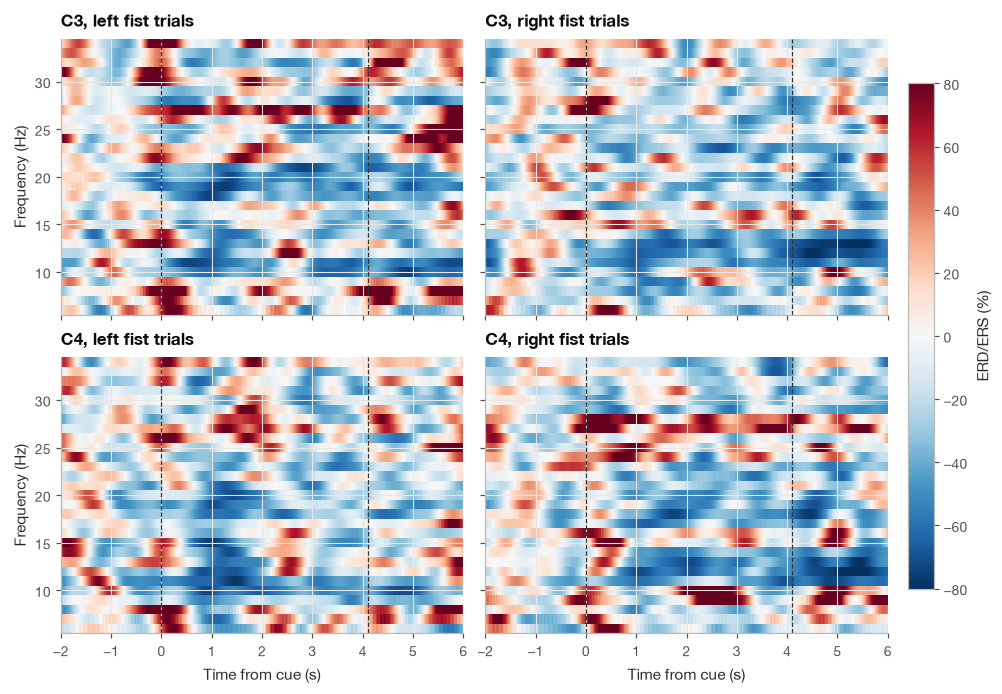

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6.2), sharex=True, sharey=True)
show = (t_erd >= -2) & (t_erd <= 6)
for row, (ch, k) in enumerate((("C3", 0), ("C4", 1))):
    for col, cls in enumerate(("Left fist", "Right fist")):
        ax = axes[row, col]
        im = ax.imshow(tf_maps[cls][k][:, show], aspect="auto", origin="lower", cmap="RdBu_r", vmin=-80, vmax=80,
                       extent=(t_erd[show][0], t_erd[show][-1], centers[0] - 0.5, centers[-1] + 0.5))
        for t_line in (0, 4.1):
            ax.axvline(t_line, color="0.2", lw=0.8, ls="--")
        ax.set_title(f"{ch}, {cls.lower()} trials")
        if col == 0:
            ax.set_ylabel("Frequency (Hz)")
        if row == 1:
            ax.set_xlabel("Time from cue (s)")
cbar = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.02)
cbar.set_label("ERD/ERS (%)")
plt.show()

Blue regions are desynchronization and red regions synchronization relative to the reference interval; the dashed lines mark the cue and the end of the target. The maps confirm the band-limited curves: a broad decrease from roughly 8 to 30 Hz that begins shortly after the cue and lasts through the movement period, deepest around XX Hz. They also show how noisy a single subject's map is when it rests on seven or eight trials. Isolated red and blue patches outside the movement period are of the size we should expect by chance, and I would not interpret any feature of these maps that is not also visible in the band-averaged curves and in individual trials.

## Summary

Event-related EEG activity comes in two kinds. Phase-locked activity has the same waveform on every trial and survives averaging; activity that is only time-locked changes the amplitude of an ongoing rhythm whose phase is random across trials, so its expected value is zero, but its expected power, $a^2(t)/2$, is not (equations 20.11 and 20.12). ERPs are therefore measured by averaging the trials, and ERD/ERS by averaging band power. On a synthetic P300 added to real resting EEG we saw the practical side of ERP work: baseline correction removes each epoch's offset at the small cost derived in (13.14), a peak-to-peak rule on the frontopolar channels rejects eye artifacts if the threshold is set from the data, a pointwise $t$-based band from the standard error (13.13) shows how uncertain the average is, and mean amplitudes are unbiased where peak amplitudes and latencies are biased and unstable with few trials. On real hand-movement data, the mu and beta rhythms at C3 and C4 desynchronized during movement in every trial, with a modest contralateral bias in the mu band that did not survive a change of montage and was inconsistent for imagined movement, a result that is about as strong as 15 trials allow.

The band-pass, square and average procedure and the filter-bank time–frequency map are the simplest members of a larger family. Chapter 23 treats the short-time Fourier transform, the continuous wavelet transform and the Hilbert envelope, which give better control over the time–frequency resolution of exactly these maps, and Section 25.2 introduces independent component analysis, a better answer to eye artifacts than rejecting epochs.

## Exercises

1. Starting from equation (13.10) with $s(t) = 0$, derive the expected value of the intertrial variance (13.16) and show that it equals $\mathbb{E}[x_i^2(t)]$. Then let $s(t) \ne 0$ and show that the difference between the classical power and the intertrial variance is approximately $s^2(t)$ for large $N$.
2. Show that ERD in percent and power change in decibels are related by $\mathrm{ERD} = 100\,(10^{\mathrm{dB}/10} - 1)$. Compute the dB values of $-25\%$, $-50\%$, $-75\%$, $+50\%$ and $+100\%$, and explain why averaging ERD percentages across subjects can be misleading when some subjects show large ERS.
3. Generalize equation (13.14) to noise with autocorrelation $R_w[k]$, and show that the extra variance added by baseline correction is the variance of the baseline mean, $\frac{1}{M^2}\sum_{m}\sum_{m'} R_w[m - m']$. Evaluate it numerically for the background EEG at Pz in R01 and compare it with the white-noise value $\sigma_w^2/M$.
4. In the synthetic ERP of [Section 13.3.3](#sec-13-3-3), let the P300 latency vary across trials with a standard deviation of 50 ms. Use the result of [Section 10.1](../ch16_noise_removal/01_signal_averaging.ipynb) to predict the peak amplitude of the averaged P300, then check the prediction. Does the mean amplitude in 300–450 ms change as much as the peak?
5. Repeat the ERD analysis of R03 with the reference interval moved to $-1.0$ to $-0.25$ s and to $-3.5$ to $-2.5$ s (extend the epochs as needed). How much do the mu ERD values and the beta curves after the movement change? Relate your answer to the short rest periods of the design.
6. Using all 64 channels of R03, compute the mean mu ERD in the 0.5–3.5 s window for left-fist and right-fist trials and draw the two topographic maps, as well as their difference. Do the maps support contralateral dominance? Propose and carry out a permutation test that shuffles the class labels across trials to judge whether the difference between the maps at C3 and C4 is larger than chance.

## Further Reading

{cite:t}`luck2014` is the standard practical guide to ERP research, with careful advice on filtering, baseline correction, artifact rejection and amplitude measures. {cite:t}`pfurtscheller1999` is the classic review of ERD and ERS, including the band-power and intertrial-variance methods and the spatial patterns of mu and beta reactivity around movement. The movement data come from the BCI2000 recordings of {cite:t}`schalk2004`, distributed by PhysioNet {cite:p}`goldberger2000`, and the scalp maps were drawn with MNE-Python {cite:p}`gramfort2013`. Averaging itself, including latency jitter, is treated in [Section 10.1](../ch16_noise_removal/01_signal_averaging.ipynb) and in {cite:t}`sornmo2005`.